# LightGBM, one model per segment

Same as `lightgbm_training.ipynb`, but one model is tuned and trained on apartment-style homes (`is_apartment = 1`) and another on everything else (`is_apartment = 0`). Each home is predicted by the model of its segment and the two sets of predictions are combined at the end.

Features are still built on every sale, so community medians and lags see the whole market; only the model fitting is split.

In [1]:
import pandas as pd
import numpy as np
from lightgbm import LGBMRegressor, early_stopping
import optuna
import sys
from pathlib import Path
from dataclasses import replace
import warnings

DIR_ROOT = Path.cwd().parent.parent.parent
sys.path.insert(0, str(DIR_ROOT))

warnings.filterwarnings("ignore")

%load_ext autoreload
%autoreload 2

/home/koyo-ai/miniconda3/envs/homeless/lib/python3.14/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [17]:
SEED = 987
TRACK = "off_market"                     # "off_market" or "list_aware"
VAL_START = pd.Timestamp("2025-12-01")    # sales on or after this date are validation
N_TRIALS = 100                             # optuna trials per segment
ES_FRACTION = 0.0                         # latest share of each fold's training rows used for early stopping
K_FOLDS = 5                              # CV validates on each of the last K_FOLDS months before VAL_START
META_MONTHS = 12                          # out-of-fold predictions for the meta model also cover the last META_MONTHS months before VAL_START
MODEL_NAME = "lightgbm_split_apartment"  # file name in oof_preds/<TRACK>/, change it for each model you want in the ensemble
DEBUG = True                             # print MdAPE and MAPE for every fold
SEGMENTS = {"apartment": 1, "house": 0}  # segment name -> is_apartment value

In [3]:
import data

listings = data.load("listings")
off_market = data.load("off_market")
list_aware = data.load("list_aware")

In [4]:
from xxbonkxx_features import off_market_features, list_aware_features, make_is_apartment

make_features = off_market_features if TRACK == "off_market" else list_aware_features

train = listings[listings["date_sold"] < VAL_START]
val = listings[listings["date_sold"] >= VAL_START]

y_train = np.log(train["sold_price"])
y_val = np.log(val["sold_price"])

is_apartment = make_is_apartment(listings)

# Column names only. The matrices are built inside each fold, then again on train and val after tuning.
print(f"Features: {make_features(train.iloc[:10]).columns.tolist()}")
print(f"train: {len(train):,} sales up to {VAL_START.date()} ({is_apartment[train.index].sum():,} apartments)")
print(f"val:   {len(val):,} sales from {VAL_START.date()} ({is_apartment[val.index].sum():,} apartments)")

Features: ['square_feet', 'bedrooms', 'washrooms', 'parking', 'lot_front', 'lot_depth', 'latitude', 'longitude', 'community', 'house_type', 'house_style', 'month', 'year', 'day', 'is_apartment', 'is_apartment_x_square_feet_0', 'is_apartment_x_square_feet_1', 'is_apartment_x_bedrooms_0', 'is_apartment_x_bedrooms_1', 'is_apartment_x_washrooms_0', 'is_apartment_x_washrooms_1', 'is_apartment_x_parking_0', 'is_apartment_x_parking_1', 'square_feet_x_bedrooms', 'square_feet_x_washrooms', 'square_feet_x_parking', 'bedrooms_x_washrooms', 'bedrooms_x_parking', 'washrooms_x_parking', 'month_sin', 'month_cos', 'lag_annual', 'lag_semi_annual', 'building_sales', 'building_log_ppsf', 'building_log_price', 'building_last_log_ppsf', 'building_days_since_sale', 'repeat_log_price', 'repeat_days_since_sale', 'remarks_renovated', 'remarks_updated', 'remarks_turnkey', 'remarks_kitchen', 'remarks_premium_kitchen', 'remarks_wood_floor', 'remarks_clean', 'remarks_needs_work', 'remarks_dated', 'remarks_split_be

In [5]:
def mdape_log(y_log, pred_log):
    return 100 * np.median(np.abs(np.exp(pred_log) / np.exp(y_log) - 1))

def mape_log(y_log, pred_log):
    return 100 * np.mean(np.abs(np.exp(pred_log) / np.exp(y_log) - 1))

def mdape(y, pred):
    return 100 * np.median(np.abs(pred - y) / np.abs(y))

def mape(y, pred):
    return 100 * np.mean(np.abs(pred - y) / np.abs(y))

target_space = "log"

In [6]:
from training_utils import walk_forward_folds

CATEGORICAL_FEATURES = [
        "community",
        "house_style",
        "house_type",
    ]


def cv_months(K, end=VAL_START):
    """The K calendar months just before `end`, oldest first."""
    return pd.period_range(end=(end - pd.Timedelta(days=1)).to_period("M"), periods=K, freq="M")


def segment_fold(fold, is_apartment):
    """The part of a walk-forward fold whose homes have the given is_apartment value, in
    both the training sales and the predicted month. The is_apartment columns (and their
    interactions) are constant within a segment, so they are dropped."""
    in_train = fold.X_train["is_apartment"].astype(int) == is_apartment
    in_homes = fold.X_homes["is_apartment"].astype(int) == is_apartment
    apartment_columns = [col for col in fold.X_train.columns if col.startswith("is_apartment")]
    return replace(
        fold,
        homes=fold.homes.loc[in_homes[in_homes].index],
        X_train=fold.X_train.loc[in_train].drop(columns=apartment_columns),
        y_train=fold.y_train.loc[in_train],
        X_homes=fold.X_homes.loc[in_homes].drop(columns=apartment_columns),
    )


def cross_val(folds, y, params, debug=False, target_space="log"):
    """Monthly walk-forward CV, the way `python run.py validate` works: each fold
    predicts one month's sales (answers hidden) with a model trained on every earlier sale.
    `folds` comes from walk_forward_folds, so features are built once, not per trial.
    `y` is indexed like the homes the folds were built from. Early stopping uses the
    latest ES_FRACTION of each fold's training rows, never the validated month.
    Returns (mean validation loss, mean boosting rounds used) over the folds."""
    mdape_scores = []
    mape_scores = []
    rounds = []
    for fold in folds:
        X_tr, X_va = fold.X_train, fold.X_homes
        n_fit = int(len(X_tr) * (1 - ES_FRACTION))
        X_fit, X_es = X_tr.iloc[:n_fit], X_tr.iloc[n_fit:]
        y_fit, y_es, y_va = y.loc[X_fit.index], y.loc[X_es.index], y.loc[X_va.index]

        model = LGBMRegressor(**params, random_state=SEED, verbosity=-1)
        model.fit(X_fit, y_fit, categorical_feature=CATEGORICAL_FEATURES)
        rounds.append(model.best_iteration_)
        pred = model.predict(X_va)
        if target_space == "log":
            mdape_scores.append(mdape_log(y_va, pred))
            mape_scores.append(mape_log(y_va, pred))
        else:
            mdape_scores.append(mdape(y_va, pred))
            mape_scores.append(mape(y_va, pred))

        if debug:
            mdape_error = mdape_scores[-1]
            mape_error = mape_scores[-1]
            print(f"{fold.month}: train {len(X_fit):,}  early stop {len(X_es):,}  val {len(X_va):,}  "
                  f"rounds {rounds[-1]}  MdAPE {mdape_error:.2f}%  MAPE {mape_error:.2f}%", flush=True)

    print(f"mean MdAPE {np.mean(mdape_scores):.2f}%  mean MAPE {np.mean(mape_scores):.2f}%", flush=True)
    return np.mean(mdape_scores), int(np.mean(rounds))

In [7]:
# Built once and shared by every trial of both segments: the last K_FOLDS months before VAL_START.
cv_folds = walk_forward_folds(train, make_features, TRACK, months=cv_months(K_FOLDS))
print("CV months:", ", ".join(str(fold.month) for fold in cv_folds))

segment_cv_folds = {
    segment: [segment_fold(fold, flag) for fold in cv_folds]
    for segment, flag in SEGMENTS.items()
}

def make_objective(folds):
    def objective(trial):
        params = {
            "learning_rate": trial.suggest_float("learning_rate", 0.01, 0.1, step=0.01),
            "num_leaves": trial.suggest_int("num_leaves", 15, 255),
            "max_depth": trial.suggest_int("max_depth", 3, 13),
            "n_estimators": trial.suggest_int("n_estimators", 200, 2000, step=200),
            "colsample_bytree": trial.suggest_float("colsample_bytree", 0.1, 1.0, step=0.1),
            "min_child_samples": trial.suggest_int("min_child_samples", 5, 100),
            "min_split_gain": trial.suggest_float("min_split_gain", 0, 0.1, step=0.01),
            "reg_lambda": trial.suggest_float("reg_lambda", 1e-3, 10.0, log=True),
            "reg_alpha": trial.suggest_float("reg_alpha", 1e-3, 10.0, log=True),
            "metric": "mae",
            "device": "gpu"
        }
        score, n_rounds = cross_val(folds, y_train, params, debug=DEBUG, target_space=target_space)
        trial.set_user_attr("n_rounds", n_rounds)
        return score
    return objective

CV months: 2025-07, 2025-08, 2025-09, 2025-10, 2025-11


In [8]:
studies = {}
for segment, flag in SEGMENTS.items():
    print(f"\n===== {segment} (is_apartment = {flag}) =====")
    study = optuna.create_study(
        direction="minimize",
        sampler=optuna.samplers.TPESampler(seed=SEED),
        study_name=f"lightgbm_{segment}",
    )
    study.optimize(make_objective(segment_cv_folds[segment]), n_trials=N_TRIALS)
    studies[segment] = study

for segment, study in studies.items():
    print(f"\n{segment}")
    print("  best CV MdAPE:", round(study.best_value, 2))
    print("  best params:", study.best_params)
    print("  boosting rounds:", study.best_trial.user_attrs["n_rounds"])

[I 2026-11-03 08:12:55,833] A new study created in memory with name: lightgbm_apartment



===== apartment (is_apartment = 1) =====
2025-07: train 76,469  early stop 0  val 1,115  rounds 0  MdAPE 6.26%  MAPE 8.56%
2025-08: train 77,584  early stop 0  val 951  rounds 0  MdAPE 5.95%  MAPE 8.07%
2025-09: train 78,535  early stop 0  val 1,039  rounds 0  MdAPE 5.84%  MAPE 8.26%
2025-10: train 79,574  early stop 0  val 1,193  rounds 0  MdAPE 5.77%  MAPE 7.78%
2025-11: train 80,767  early stop 0  val 989  rounds 0  MdAPE 6.22%  MAPE 8.12%
mean MdAPE 6.01%  mean MAPE 8.16%


[I 2026-11-03 08:13:10,886] Trial 0 finished with value: 6.008109872907141 and parameters: {'learning_rate': 0.05, 'num_leaves': 109, 'max_depth': 12, 'n_estimators': 1000, 'colsample_bytree': 0.9, 'min_child_samples': 93, 'min_split_gain': 0.1, 'reg_lambda': 7.103714746188992, 'reg_alpha': 0.0013187949354214168}. Best is trial 0 with value: 6.008109872907141.


2025-07: train 76,469  early stop 0  val 1,115  rounds 0  MdAPE 6.28%  MAPE 8.74%
2025-08: train 77,584  early stop 0  val 951  rounds 0  MdAPE 6.17%  MAPE 8.52%
2025-09: train 78,535  early stop 0  val 1,039  rounds 0  MdAPE 6.18%  MAPE 8.52%
2025-10: train 79,574  early stop 0  val 1,193  rounds 0  MdAPE 5.96%  MAPE 8.04%
2025-11: train 80,767  early stop 0  val 989  rounds 0  MdAPE 6.22%  MAPE 8.42%
mean MdAPE 6.16%  mean MAPE 8.45%


[I 2026-11-03 08:13:33,644] Trial 1 finished with value: 6.160422172019096 and parameters: {'learning_rate': 0.01, 'num_leaves': 223, 'max_depth': 3, 'n_estimators': 1600, 'colsample_bytree': 0.8, 'min_child_samples': 34, 'min_split_gain': 0.02, 'reg_lambda': 1.1275113496020217, 'reg_alpha': 4.791227993546376}. Best is trial 0 with value: 6.008109872907141.


2025-07: train 76,469  early stop 0  val 1,115  rounds 0  MdAPE 6.23%  MAPE 8.51%
2025-08: train 77,584  early stop 0  val 951  rounds 0  MdAPE 5.87%  MAPE 7.97%
2025-09: train 78,535  early stop 0  val 1,039  rounds 0  MdAPE 5.86%  MAPE 8.19%
2025-10: train 79,574  early stop 0  val 1,193  rounds 0  MdAPE 5.91%  MAPE 7.74%
2025-11: train 80,767  early stop 0  val 989  rounds 0  MdAPE 5.94%  MAPE 8.00%
mean MdAPE 5.96%  mean MAPE 8.08%


... (392 outputs left out)

[I 2026-11-03 18:36:41,977] Trial 98 finished with value: 9.68088592621283 and parameters: {'learning_rate': 0.01, 'num_leaves': 233, 'max_depth': 11, 'n_estimators': 1800, 'colsample_bytree': 0.6, 'min_child_samples': 51, 'min_split_gain': 0.0, 'reg_lambda': 6.24471326666518, 'reg_alpha': 0.06471278791258243}. Best is trial 70 with value: 9.532493982580288.


2025-07: train 53,576  early stop 0  val 953  rounds 0  MdAPE 10.52%  MAPE 12.96%
2025-08: train 54,529  early stop 0  val 715  rounds 0  MdAPE 10.02%  MAPE 12.73%
2025-09: train 55,244  early stop 0  val 996  rounds 0  MdAPE 9.47%  MAPE 11.92%
2025-10: train 56,240  early stop 0  val 1,057  rounds 0  MdAPE 9.11%  MAPE 11.69%
2025-11: train 57,297  early stop 0  val 878  rounds 0  MdAPE 9.49%  MAPE 12.37%
mean MdAPE 9.72%  mean MAPE 12.33%


[I 2026-11-03 18:42:37,333] Trial 99 finished with value: 9.722315845054052 and parameters: {'learning_rate': 0.01, 'num_leaves': 240, 'max_depth': 11, 'n_estimators': 2000, 'colsample_bytree': 0.6, 'min_child_samples': 61, 'min_split_gain': 0.0, 'reg_lambda': 9.770108893944236, 'reg_alpha': 0.06199162548225773}. Best is trial 70 with value: 9.532493982580288.



apartment
  best CV MdAPE: 5.5
  best params: {'learning_rate': 0.03, 'num_leaves': 195, 'max_depth': 6, 'n_estimators': 1800, 'colsample_bytree': 0.4, 'min_child_samples': 68, 'min_split_gain': 0.0, 'reg_lambda': 0.0017675392438743578, 'reg_alpha': 1.5005788903973847}
  boosting rounds: 0

house
  best CV MdAPE: 9.53
  best params: {'learning_rate': 0.03, 'num_leaves': 248, 'max_depth': 10, 'n_estimators': 1000, 'colsample_bytree': 0.6, 'min_child_samples': 13, 'min_split_gain': 0.0, 'reg_lambda': 1.482210462847529, 'reg_alpha': 0.5155994576469242}
  boosting rounds: 0


In [9]:
from optuna.importance import get_param_importances

for segment, study in studies.items():
    print(f"\n{segment}")
    for param, score in get_param_importances(study).items():
        print(f"  {param}: {score:.4f}")


apartment
  learning_rate: 0.1990
  min_split_gain: 0.1834
  reg_alpha: 0.1692
  max_depth: 0.1083
  reg_lambda: 0.1073
  num_leaves: 0.1004
  min_child_samples: 0.0533
  colsample_bytree: 0.0530
  n_estimators: 0.0261

house
  min_split_gain: 0.2095
  reg_lambda: 0.1619
  colsample_bytree: 0.1404
  max_depth: 0.1275
  num_leaves: 0.1124
  reg_alpha: 0.1048
  min_child_samples: 0.0619
  learning_rate: 0.0557
  n_estimators: 0.0260


In [10]:
from training_utils import walk_forward_validate

def make_fit_model(params):
    def fit_model(X_train, y_train):
        model = LGBMRegressor(**params,
                              subsample_freq=1,
                              importance_type="gain",
                              random_state=SEED,
                              verbosity=-1)
        return model.fit(X_train, y_train)
    return fit_model

fit_models = {segment: make_fit_model(study.best_params) for segment, study in studies.items()}

folds = walk_forward_folds(listings, make_features, TRACK)
validations = {}
for segment, flag in SEGMENTS.items():
    print(f"\n===== {segment} (is_apartment = {flag}) =====")
    segment_folds = [segment_fold(fold, flag) for fold in folds]
    validations[segment] = walk_forward_validate(
        listings, make_features, fit_models[segment], TRACK, folds=segment_folds
    )


===== apartment (is_apartment = 1) =====
2025-12: trained on 81,756 earlier sales, predicted 700 homes  MdAPE 5.53%  MAPE 7.52%
2026-01: trained on 82,456 earlier sales, predicted 679 homes  MdAPE 5.65%  MAPE 7.90%
2026-02: trained on 83,135 earlier sales, predicted 816 homes  MdAPE 5.67%  MAPE 7.45%
2026-03: trained on 83,951 earlier sales, predicted 1,019 homes  MdAPE 5.74%  MAPE 8.22%
2026-04: trained on 84,970 earlier sales, predicted 1,202 homes  MdAPE 5.56%  MAPE 7.41%
2026-05: trained on 86,172 earlier sales, predicted 1,091 homes  MdAPE 5.03%  MAPE 7.43%
off_market  MdAPE 5.54%  MAPE 7.64%

===== house (is_apartment = 0) =====
2025-12: trained on 58,175 earlier sales, predicted 538 homes  MdAPE 9.34%  MAPE 11.80%
2026-01: trained on 58,713 earlier sales, predicted 379 homes  MdAPE 9.92%  MAPE 12.24%
2026-02: trained on 59,092 earlier sales, predicted 626 homes  MdAPE 8.75%  MAPE 11.51%
2026-03: trained on 59,718 earlier sales, predicted 797 homes  MdAPE 8.14%  MAPE 10.61%
2026

In [11]:
for segment, validation in validations.items():
    feature_importances = pd.Series(
        validation.model.feature_importances_, index=validation.X_train.columns
    ).sort_values(ascending=False)
    print(f"===== {segment} =====")
    print("Most Important Features:")
    print(feature_importances.head(20))
    print("\n")
    print("Least Important Features:")
    print(feature_importances.tail(20))
    print("\n")

===== apartment =====
Most Important Features:
building_log_price         61367.738979
square_feet_x_washrooms    20885.180511
community                  16205.904513
building_last_log_ppsf      9270.980653
building_log_ppsf           9257.525834
square_feet_x_parking       4589.150955
square_feet                 4494.538322
washrooms                   3095.177664
remarks_text_score          2334.876403
square_feet_x_bedrooms      2252.900212
day                         1511.443461
washrooms_x_parking         1458.899805
repeat_log_price             848.824784
remarks_condition_score      714.272668
remarks_needs_work           690.789445
remarks_renovated            544.530414
house_type                   430.321189
bedrooms_x_washrooms         367.934454
year                         364.418835
building_sales               362.288497
dtype: float64


Least Important Features:
remarks_locker                 3.091638
remarks_rooftop_terrace        3.033914
remarks_ensuite_laundry       

In [12]:
# Combine: every validation home was predicted by the model of its own segment.
predictions = pd.concat([validation.predictions for validation in validations.values()])
predictions = predictions.sort_values(["month", "ml_num"])
X_val = pd.concat([fold.X_homes for fold in folds]).loc[predictions.index]
actual, predicted = predictions["sold_price"], predictions["predicted_price"]

def print_errors(label, actual, predicted):
    error = 100 * np.abs(predicted / actual - 1)
    print(f"{label:<10} {len(error):>7,} homes  MdAPE {error.median():.2f}%  MAPE {error.mean():.2f}%")

for segment, validation in validations.items():
    print_errors(segment, validation.actual, validation.predicted)
print_errors("combined", actual, predicted)

print("\nCombined, by month:")
for month, group in predictions.groupby("month"):
    print_errors(month, group["sold_price"], group["predicted_price"])

apartment    5,507 homes  MdAPE 5.54%  MAPE 7.64%
house        4,562 homes  MdAPE 8.97%  MAPE 11.41%
combined    10,069 homes  MdAPE 6.82%  MAPE 9.35%

Combined, by month:
2025-12      1,238 homes  MdAPE 6.80%  MAPE 9.38%
2026-01      1,058 homes  MdAPE 6.89%  MAPE 9.46%
2026-02      1,442 homes  MdAPE 6.74%  MAPE 9.21%
2026-03      1,816 homes  MdAPE 6.73%  MAPE 9.27%
2026-04      2,224 homes  MdAPE 6.88%  MAPE 9.32%
2026-05      2,291 homes  MdAPE 6.85%  MAPE 9.47%


In [13]:
from training_utils import save_oof_predictions

meta_folds = walk_forward_folds(listings, make_features, TRACK, months=cv_months(META_MONTHS))
print("Meta model training months:", ", ".join(str(fold.month) for fold in meta_folds))

meta_validations = {}
for segment, flag in SEGMENTS.items():
    print(f"\n===== {segment} (is_apartment = {flag}) =====")
    segment_folds = [segment_fold(fold, flag) for fold in meta_folds]
    meta_validations[segment] = walk_forward_validate(
        listings, make_features, fit_models[segment], TRACK, folds=segment_folds
    )

save_oof_predictions(MODEL_NAME, *meta_validations.values(), *validations.values())

Meta model training months: 2025-06, 2025-07, 2025-08, 2025-09, 2025-10, 2025-11

===== apartment (is_apartment = 1) =====
2025-06: trained on 75,347 earlier sales, predicted 1,122 homes  MdAPE 5.65%  MAPE 7.31%
2025-07: trained on 76,469 earlier sales, predicted 1,115 homes  MdAPE 5.92%  MAPE 7.99%
2025-08: trained on 77,584 earlier sales, predicted 951 homes  MdAPE 5.28%  MAPE 7.34%
2025-09: trained on 78,535 earlier sales, predicted 1,039 homes  MdAPE 5.33%  MAPE 7.59%
2025-10: trained on 79,574 earlier sales, predicted 1,193 homes  MdAPE 5.45%  MAPE 7.36%
2025-11: trained on 80,767 earlier sales, predicted 989 homes  MdAPE 5.54%  MAPE 7.68%
off_market  MdAPE 5.54%  MAPE 7.54%

===== house (is_apartment = 0) =====
2025-06: trained on 52,415 earlier sales, predicted 1,161 homes  MdAPE 9.49%  MAPE 11.84%
2025-07: trained on 53,576 earlier sales, predicted 953 homes  MdAPE 10.06%  MAPE 12.82%
2025-08: trained on 54,529 earlier sales, predicted 715 homes  MdAPE 10.18%  MAPE 12.87%
2025-

PosixPath('/home/koyo-ai/ssd2/private/SSU-Data-Dash/notebooks/xxbonkxx/models/oof_preds/off_market/lightgbm_split_apartment.parquet')

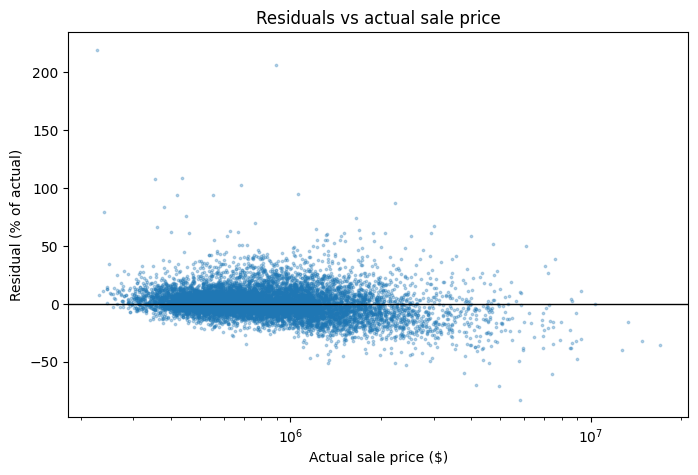

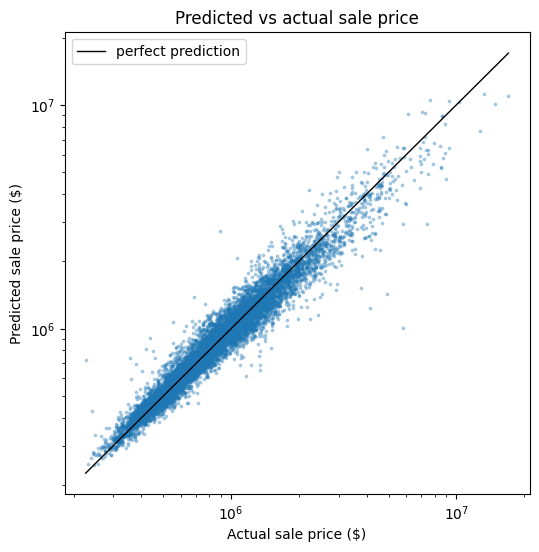

In [14]:
import diagnostics

diagnostics.plot_residuals_vs_actual(actual, predicted)
diagnostics.plot_predicted_vs_actual(actual, predicted)



In [15]:
import matplotlib.pyplot as plt
import seaborn as sns

def plot_residuals_by_feature(X, actual, predicted, max_categories=20, n_cols=3):
    """One panel per column of X: a scatter plot for continuous columns and a box plot
    for categorical ones. Numeric columns with at most max_categories distinct values
    (bedrooms, month, ...) count as categorical. Columns with more categories than that
    show only their max_categories most common values."""
    residual = percent_error(actual, predicted)
    n_rows = int(np.ceil(len(X.columns) / n_cols))
    fig, axes = plt.subplots(n_rows, n_cols, figsize=(6 * n_cols, 4 * n_rows), squeeze=False)

    for ax, column in zip(axes.flat, X.columns):
        values = X[column].to_numpy()
        is_numeric = pd.api.types.is_numeric_dtype(X[column])
        if is_numeric and X[column].nunique() > max_categories:
            ax.scatter(values, residual, s=3, alpha=0.3)
        else:
            if is_numeric:
                order = sorted(X[column].value_counts().index[:max_categories])
            else:
                order = (
                    pd.DataFrame({"category": X[column], "residual": residual})
                    .groupby("category")["residual"]
                    .mean()
                    .sort_values(ascending=False)
                    .head(max_categories)
                    .index
                    .tolist()
                )
            sns.boxplot(x=values, y=residual, order=order, showfliers=False, ax=ax)
            ax.tick_params(axis="x", rotation=90)
        ax.axhline(0, color="black", linewidth=1)
        ax.set(title=column, xlabel="", ylabel="Residual (%)")

    for ax in axes.flat[len(X.columns):]:
        ax.set_visible(False)
    fig.tight_layout()
    plt.show()

def percent_error(actual, predicted):
    return 100 * (np.asarray(predicted) / np.asarray(actual) - 1)

plot_residuals_by_feature(X_val, actual, predicted)

In [16]:
def evaluate_by_quantile(y_true, y_pred, n_bins=10):
    df = pd.DataFrame({
        "actual": y_true,
        "predicted": y_pred
    })
    df["quantile"] = pd.qcut(
        df["actual"], q=n_bins, duplicates="drop"
    )
    df["residual"] = df["actual"] - df["predicted"]
    df["residual_percent"] = 100 * np.abs(df["residual"]) / df["actual"]
    return df.groupby("quantile", observed=True).agg(
        count=("actual", "size"),
        MAE=("residual", lambda x: x.abs().mean()),
        mean_residual=("residual", "mean"),
        mean_residual_percent=("residual_percent", "mean"),
        mdape=("residual_percent", lambda x: np.median(np.abs(x))),
        mape=("residual_percent", lambda x: np.mean(np.abs(x)))
    )

evaluate_by_quantile(actual, predicted, n_bins=20)

,count,MAE,mean_residual,mean_residual_percent,mdape,mape
quantile,,,,,,
"(226199.999, 388140.0]",504,27832.454365,-20021.311508,8.312953,5.504096,8.312953
"(388140.0, 440480.0]",503,29250.103380,-16303.192843,7.008011,5.136461,7.008011
"(440480.0, 482100.0]",505,29655.398020,-12391.227723,6.414077,4.916757,6.414077
"(482100.0, 521000.0]",503,32270.918489,-9833.284294,6.425295,5.165288,6.425295
"(521000.0, 558000.0]",503,39382.115308,-13304.166998,7.289195,5.403275,7.289195
"(558000.0, 597040.0]",503,43880.230616,-15228.632207,7.588706,5.448403,7.588706
"(597040.0, 643360.0]",503,44499.779324,-14144.506958,7.170948,5.364098,7.170948
"(643360.0, 692020.0]",504,53653.291667,-18937.176587,8.041362,5.951394,8.041362
"(692020.0, 747620.0]",503,59269.485089,-18779.512922,8.236118,6.145355,8.236118
